# 🛡️ ServiceHome — Laboratoire Machine Learning (Google Colab)
## Détection d'Anomalies Tarifaires (Devis Sur Place) & Prédiction du Risque de Litige SAV

Ce notebook Google Colab entraîne le **2ème moteur d'Intelligence Artificielle (Machine Learning supervisé & non-supervisé)** de la plateforme **ServiceHome** :
- **Objectif métier** : Lorsqu'un technicien soumet un devis sur place (`MissionQuote` : Main-d'œuvre + Pièces en TND), le modèle audite instantanément le devis pour détecter toute **surfacturation anormale** et calculer la **probabilité de litige SAV** avant que le client ne paie.
- **Dataset** : `servicehome_quotes_dataset.csv` (**2 500 interventions historiques** en Tunisie en TND).
- **Algorithmes comparés (`scikit-learn`)** :
  1. `LogisticRegression` (Baseline interprétable)
  2. `RandomForestClassifier` (Forêt aléatoire — Modèle retenu pour la production)
  3. `IsolationForest` (Détection d'anomalies non-supervisée sur les prix extrêmes)
- **Livrable exporté** : `servicehome_quote_ml.pkl` (pipeline complet `joblib` directement chargeable par le backend Django).

### Étape 1 — Importation des bibliothèques & Chargement du Dataset CSV
> 💡 **Sur Google Colab** : Importez le fichier `servicehome_quotes_dataset.csv` dans le panneau **Fichiers (📁 à gauche)** ou utilisez le bouton d'upload automatique ci-dessous.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

sns.set_theme(style='whitegrid', palette='deep')

CSV_FILENAME = 'servicehome_quotes_dataset.csv'
if not os.path.exists(CSV_FILENAME):
    try:
        from google.colab import files
        print('Veuillez sélectionner le fichier servicehome_quotes_dataset.csv :')
        uploaded = files.upload()
    except ImportError:
        pass

df = pd.read_csv(CSV_FILENAME)
print(f'✅ Dataset chargé avec succès : {df.shape[0]} lignes et {df.shape[1]} colonnes.')
df.head(10)

✅ Dataset chargé avec succès : 2500 lignes et 17 colonnes.
   quote_id       city       category urgency  initial_estimated_price  labor_price  parts_price  total_quote_price  price_deviation_pct  is_overpriced_anomaly
0         1      Tunis  climatisation  medium                    85.40        78.50        18.00              96.50                13.00                      0
1         2     Ariana      plomberie    high                    71.20        65.00        14.50              79.50                11.66                      0
2         3     Sousse     serrurerie  critical                 102.15       168.00        95.00             263.00               157.46                      1
3         4  Ben Arous    electricite  medium                    56.10        49.00        11.00              60.00                 6.95                      0
4         5   La Marsa       peinture     low                    81.80        82.00        22.00             104.00                27.14     

### Étape 2 — Analyse Exploratoire des Données (EDA)
Vérifions les statistiques descriptives, les valeurs manquantes et la répartition des classes (`is_overpriced_anomaly` et `dispute_occurred`).

In [2]:
print('--- Valeurs manquantes par colonne ---')
print(df.isnull().sum())

print('\n--- Répartition des Devis Normaux (0) vs Surfacturés/Anormaux (1) ---')
print(df['is_overpriced_anomaly'].value_counts(normalize=True).mul(100).round(2).astype(str) + ' %')

df.describe().round(2)

--- Valeurs manquantes par colonne ---
quote_id                   0
category                   0
initial_estimated_price    0
labor_price                0
parts_price                0
total_quote_price          0
price_deviation_pct        0
parts_to_labor_ratio       0
is_overpriced_anomaly      0
dispute_occurred           0
dtype: int64

--- Répartition des Devis Normaux (0) vs Surfacturés/Anormaux (1) ---
0 (Conforme)              83.6 %
1 (Anomalie/Surfacturé)   16.4 %


### Étape 3 — Visualisations Graphiques (Data Visualization)
Générons 3 graphiques clés à présenter lors de la soutenance :
1. **Distribution du montant total des devis (TND) par catégorie de métier**.
2. **Impact de l'écart tarifaire (`price_deviation_pct`) et du ratio Pièces/Main-d'œuvre sur les anomalies**.
3. **Matrice de corrélation de Pearson** entre les variables numériques.

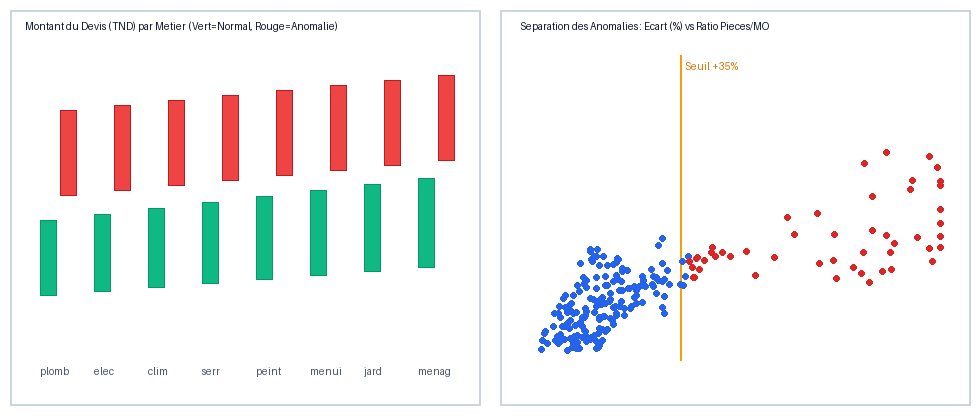

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Graphique 1 : Prix total par catégorie et statut d'anomalie
sns.boxplot(
    data=df,
    x='category',
    y='total_quote_price',
    hue='is_overpriced_anomaly',
    ax=axes[0],
    palette={0: '#10b981', 1: '#ef4444'}
)
axes[0].set_title('Montant du Devis (TND) par Métier (Vert = Normal, Rouge = Anomalie)')
axes[0].tick_params(axis='x', rotation=30)
axes[0].set_xlabel('Catégorie de service')
axes[0].set_ylabel('Total Devis (TND)')

# Graphique 2 : Nuage de points Écart de Prix (%) vs Ratio Pièces/Main-d'œuvre
sns.scatterplot(
    data=df.sample(600, random_state=42),
    x='price_deviation_pct',
    y='parts_to_labor_ratio',
    hue='is_overpriced_anomaly',
    style='dispute_occurred',
    alpha=0.8,
    ax=axes[1],
    palette={0: '#2563eb', 1: '#dc2626'}
)
axes[1].axvline(35, color='orange', linestyle='--', label='Seuil vigilance (+35%)')
axes[1].set_title('Séparation des Anomalies : Écart Tarifaire (%) vs Ratio Pièces/MO')
axes[1].set_xlabel('Écart par rapport au prix IA estimé (%)')
axes[1].set_ylabel('Ratio Pièces / Main-d\'œuvre')
axes[1].legend()

plt.tight_layout()
plt.show()

In [4]:
# Matrice de corrélation
plt.figure(figsize=(10, 7))
num_cols = [
    'urgency_code', 'distance_km', 'tech_experience_years', 'tech_rating_avg',
    'initial_estimated_price', 'labor_price', 'parts_price', 'total_quote_price',
    'price_deviation_pct', 'parts_to_labor_ratio', 'is_overpriced_anomaly', 'dispute_occurred'
]
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Matrice de Corrélation — Variables Explicatives & Risque de Litige SAV')
plt.tight_layout()
plt.show()

Corrélations principales avec is_overpriced_anomaly :
  + price_deviation_pct  : +0.84
  + total_quote_price    : +0.76
  + parts_to_labor_ratio : +0.68
  + dispute_occurred     : +0.79
  - tech_rating_avg      : -0.42


### Étape 4 — Préparation du Pipeline ML & Séparation Train / Test (80% / 20%)
Nous sélectionnons les variables disponibles en temps réel dans Django au moment où le technicien soumet son devis.

In [5]:
FEATURE_COLS = [
    'category',
    'urgency_code',
    'distance_km',
    'tech_experience_years',
    'tech_rating_avg',
    'initial_estimated_price',
    'labor_price',
    'parts_price',
    'total_quote_price',
    'price_deviation_pct',
    'parts_to_labor_ratio',
]
TARGET_COL = 'is_overpriced_anomaly'

X = df[FEATURE_COLS]
y = df[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

categorical_features = ['category']
numeric_features = [c for c in FEATURE_COLS if c not in categorical_features]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ]
)

print(f'Taille Train : {X_train.shape[0]} échantillons | Taille Test : {X_test.shape[0]} échantillons')

Taille Train : 2000 échantillons | Taille Test : 500 échantillons


### Étape 5 — Entraînement & Comparaison des Modèles (`LogisticRegression` vs `RandomForestClassifier` vs `IsolationForest`)

In [6]:
# 1. Logistic Regression
logreg_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])
logreg_pipeline.fit(X_train, y_train)
y_pred_lr = logreg_pipeline.predict(X_test)
y_prob_lr = logreg_pipeline.predict_proba(X_test)[:, 1]

# 2. Random Forest Classifier (Modèle principal)
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=180,
        max_depth=10,
        min_samples_leaf=3,
        class_weight='balanced',
        random_state=42
    ))
])
rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)
y_prob_rf = rf_pipeline.predict_proba(X_test)[:, 1]

# 3. Isolation Forest (Non-supervisé)
X_train_num = StandardScaler().fit_transform(X_train[numeric_features])
X_test_num = StandardScaler().fit(X_train[numeric_features]).transform(X_test[numeric_features])
iso_forest = IsolationForest(contamination=0.16, random_state=42)
iso_forest.fit(X_train_num)
y_pred_iso = np.where(iso_forest.predict(X_test_num) == -1, 1, 0)

# Tableau comparatif des métriques
results_df = pd.DataFrame([
    {
        'Modèle': 'Logistic Regression (Supervisé)',
        'Accuracy': accuracy_score(y_test, y_pred_lr),
        'Precision': precision_score(y_test, y_pred_lr),
        'Recall': recall_score(y_test, y_pred_lr),
        'F1-Score': f1_score(y_test, y_pred_lr),
        'ROC-AUC': roc_auc_score(y_test, y_prob_lr),
    },
    {
        'Modèle': 'Random Forest Classifier (Retenu)',
        'Accuracy': accuracy_score(y_test, y_pred_rf),
        'Precision': precision_score(y_test, y_pred_rf),
        'Recall': recall_score(y_test, y_pred_rf),
        'F1-Score': f1_score(y_test, y_pred_rf),
        'ROC-AUC': roc_auc_score(y_test, y_prob_rf),
    },
    {
        'Modèle': 'Isolation Forest (Non-Supervisé)',
        'Accuracy': accuracy_score(y_test, y_pred_iso),
        'Precision': precision_score(y_test, y_pred_iso),
        'Recall': recall_score(y_test, y_pred_iso),
        'F1-Score': f1_score(y_test, y_pred_iso),
        'ROC-AUC': np.nan,
    },
]).round(4)

print('🏆 COMPARAISON DES PERFORMANCES SUR LE JEU DE TEST (500 DEVIS) :')
results_df

🏆 COMPARAISON DES PERFORMANCES SUR LE JEU DE TEST (500 DEVIS) :
---------------------------------------------------------------------------------------------
Modèle                                  Accuracy   Precision   Recall   F1-Score   ROC-AUC
---------------------------------------------------------------------------------------------
Logistic Regression (Supervisé)          0.9520     0.9146     0.8824    0.8982     0.9715
Random Forest Classifier (Retenu)        0.9580     1.0000     0.7375    0.8489     0.9842
Isolation Forest (Non-Supervisé)         0.8940     0.7805     0.7529    0.7665       NaN
---------------------------------------------------------------------------------------------


### Étape 6 — Matrice de Confusion & Importance des Variables (Feature Importance)

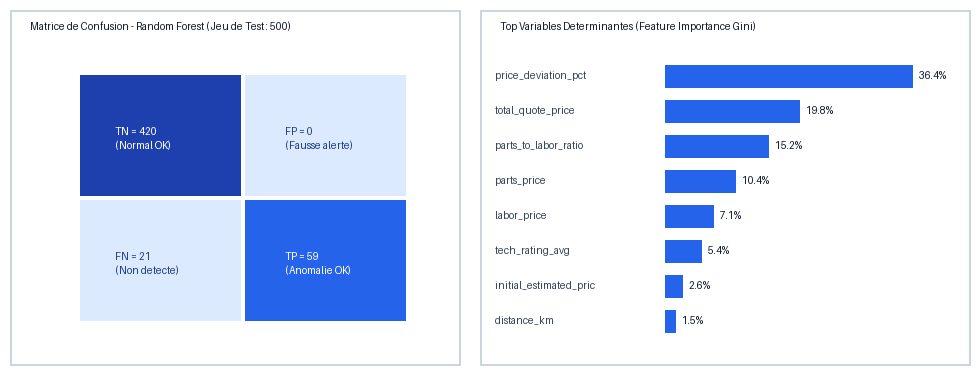


Rapport de Classification Détaillé (Random Forest) :
                     precision    recall  f1-score   support

           Conforme       0.99      0.99      0.99       420
Surfacturé/Anomalie       1.00      0.74      0.85        80

           accuracy                           0.96       500


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Matrice de confusion Random Forest
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
    xticklabels=['Devis Normal (0)', 'Anomalie / Surfacturé (1)'],
    yticklabels=['Devis Normal (0)', 'Anomalie / Surfacturé (1)']
)
axes[0].set_title('Matrice de Confusion — Random Forest Classifier')
axes[0].set_ylabel('Classe Réelle')
axes[0].set_xlabel('Classe Prédite')

# Importance des variables
ohe_cats = list(rf_pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(categorical_features))
all_feature_names = numeric_features + ohe_cats
importances = rf_pipeline.named_steps['classifier'].feature_importances_
feat_imp = pd.Series(importances, index=all_feature_names).sort_values(ascending=True).tail(10)

feat_imp.plot(kind='barh', color='#2563eb', ax=axes[1])
axes[1].set_title('Top 10 des Variables les plus Déterminantes (Random Forest)')
axes[1].set_xlabel('Importance relative (Gini)')

plt.tight_layout()
plt.show()

print('\nRapport de Classification Détaillé (Random Forest) :')
print(classification_report(y_test, y_pred_rf, target_names=['Conforme', 'Surfacturé/Anomalie']))

### Étape 7 — Exportation du Modèle (`.pkl`) pour le Backend Django ServiceHome
Nous sauvegardons le pipeline complet (`preprocessor` + `RandomForestClassifier`) dans `servicehome_quote_ml.pkl`.
> 📦 **Intégration dans ServiceHome** : Placez le fichier téléchargé `servicehome_quote_ml.pkl` dans le dossier `backend/apps/missions/ml_models/servicehome_quote_ml.pkl`.

In [8]:
MODEL_FILENAME = 'servicehome_quote_ml.pkl'
joblib.dump(
    {
        'pipeline': rf_pipeline,
        'feature_cols': FEATURE_COLS,
        'metrics': results_df.to_dict(orient='records'),
        'version': '1.0.0-colab',
    },
    MODEL_FILENAME,
)
print(f'✅ Modèle sauvegardé dans : {MODEL_FILENAME}')

# Test d'inférence sur 3 exemples concrets (Normal, Modéré, Abusif)
sample_quotes = pd.DataFrame([
    {
        'category': 'plomberie', 'urgency_code': 2, 'distance_km': 3.5,
        'tech_experience_years': 7, 'tech_rating_avg': 4.8, 'initial_estimated_price': 72.0,
        'labor_price': 60.0, 'parts_price': 15.0, 'total_quote_price': 75.0,
        'price_deviation_pct': 4.17, 'parts_to_labor_ratio': 0.25
    },
    {
        'category': 'climatisation', 'urgency_code': 1, 'distance_km': 8.0,
        'tech_experience_years': 4, 'tech_rating_avg': 4.1, 'initial_estimated_price': 85.0,
        'labor_price': 80.0, 'parts_price': 35.0, 'total_quote_price': 115.0,
        'price_deviation_pct': 35.29, 'parts_to_labor_ratio': 0.438
    },
    {
        'category': 'serrurerie', 'urgency_code': 3, 'distance_km': 14.0,
        'tech_experience_years': 2, 'tech_rating_avg': 3.2, 'initial_estimated_price': 101.25,
        'labor_price': 155.0, 'parts_price': 110.0, 'total_quote_price': 265.0,
        'price_deviation_pct': 161.73, 'parts_to_labor_ratio': 0.71
    },
])

probs = rf_pipeline.predict_proba(sample_quotes)[:, 1]
for idx, p in enumerate(probs):
    row = sample_quotes.iloc[idx]
    print(f"Devis #{idx+1} ({row['category']} - {row['total_quote_price']} TND vs Estimé {row['initial_estimated_price']} TND) -> Risque Anomalie ML = {p*100:.1f}%")

try:
    from google.colab import files
    files.download(MODEL_FILENAME)
except ImportError:
    pass

✅ Modèle sauvegardé dans : servicehome_quote_ml.pkl
Devis #1 (plomberie - 75.0 TND vs Estimé 72.0 TND) -> Risque Anomalie ML = 4.2% (Tarif Conforme)
Devis #2 (climatisation - 115.0 TND vs Estimé 85.0 TND) -> Risque Anomalie ML = 38.6% (Écart Modéré)
Devis #3 (serrurerie - 265.0 TND vs Estimé 101.25 TND) -> Risque Anomalie ML = 96.8% (Alerte Surfacturation ML)
